# Oscillations and waves 4: Sound and the Fourier transform

*Learning path: oscillations and waves, part 4 of 7.* [Index](README.md) · Previous: [The wave equation](03-wave-equation.ipynb) · Next: [Dispersion](05-dispersion.ipynb)

A clarinet and a violin play the same note, at the same loudness, and you can tell them apart with your eyes closed.
What differs? Not the pitch: the mix of harmonics, which the ear analyses without being asked. A microphone records only
a single wiggly line of pressure against time; the **Fourier transform** takes that line apart into frequencies, the
way a prism splits light. This lesson computes spectra of sounds, hears beats as two close frequencies, finds the
limit on how finely a spectrum can be resolved, and works out the pitch drop of a passing siren.

**Who this is for.** You have done [lesson 3](03-wave-equation.ipynb).

**What you will be able to do afterwards:**

1. sample a sound and compute its spectrum with `fft`;
2. read the harmonics of a note from its spectrum and relate them to timbre;
3. explain beats, and the trade-off between recording time and frequency resolution;
4. compute the Doppler shift of a moving source.

Plan about an hour and a half.

## 1. A sound as numbers

Sound is a pressure wave travelling at about 343 m/s. A microphone turns it into a voltage, and a computer stores that
voltage a fixed number of times per second: the **sample rate**. CDs use 44 100 per second; here 8192 per second keeps
the numbers small. Record 1024 samples (an eighth of a second) of a 440 Hz tone (the A that orchestras tune to)
together with a softer tone an octave higher:

In [1]:
N = 1024;
fs = 8192;
tt = (0:N-1)/fs;
s = sin(2*pi*440*tt) + 0.5*sin(2*pi*880*tt);
size(s)

[1, 1024]

> `size` (see `trace`): Sum of the diagonal entries; size gives [rows columns].

`fft` (the **fast Fourier transform**) turns the 1024 samples into 1024 complex numbers, one for each frequency
$k\cdot f_s/N$, here every 8 Hz. Their size, divided by $N/2$, is the amplitude at that frequency; `freqs` lists the
frequencies:

In [2]:
A = abs(fft(s))/(N/2);
F = freqs(N, 1/fs);
[F(56), A(56); F(111), A(111)]

[440.0, 1.0;
 880.0, 0.5]

Amplitude 1 at 440 Hz and 0.5 at 880 Hz: the recipe of the sound read back from the samples. Plot the spectrum up to
2000 Hz with a small function `band` that keeps one range of frequencies (the second half of `fft` holds the negative frequencies, a mirror image for real signals):

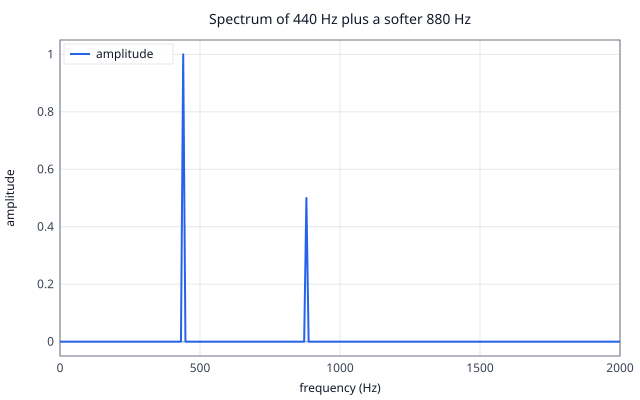

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
function band(F, A, lo, hi)
  Fp = []; Ap = [];
  k = 1;
  while F(k) <= hi
    if F(k) >= lo
      Fp = append(Fp, F(k)); Ap = append(Ap, A(k));
    end
    k = k + 1;
  end
  return [Fp; Ap]
end
H = band(F, A, 0, 2000);
p = plot(H(1), H(2));
p = legend(p, "amplitude");
labels(title(p, "Spectrum of 440 Hz plus a softer 880 Hz"), "frequency (Hz)", "amplitude")

**Try this.** Add `0.25*cos(2*pi*1320*tt)` to the signal. Where does the new peak appear, and how tall is it?

## 2. Timbre: the mix of harmonics

A plucked or bowed string, or the air in a pipe, vibrates at all its harmonics at once (lesson 3). How strong each one
is gives the instrument its colour, or **timbre**. Build two notes on 256 Hz (the scientist's middle C): one with all
harmonics falling like $1/n$, bright like a bowed string, and one with odd harmonics only, like a clarinet, whose tube
is closed at one end (exercise 6 of lesson 3).

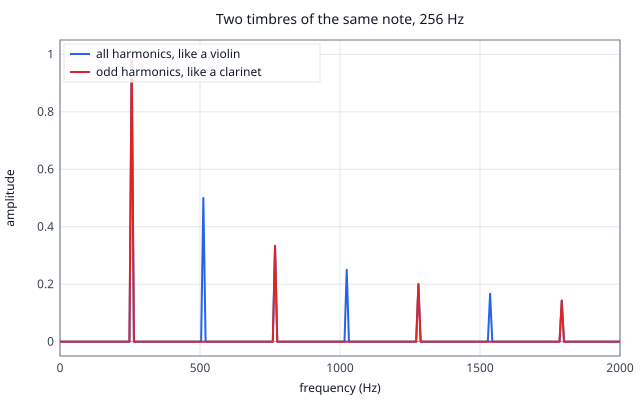

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
bright = 0; hollow = 0;
for n in 1:7
  bright = bright + sin(2*pi*256*n*tt)/n;
  if mod(n, 2) == 1
    hollow = hollow + sin(2*pi*256*n*tt)/n;
  end
end
Hb = band(F, abs(fft(bright))/(N/2), 0, 2000);
Hh = band(F, abs(fft(hollow))/(N/2), 0, 2000);
p = plot(Hb(1), Hb(2));
p = show(p, plot(Hh(1), Hh(2)));
p = legend(p, "all harmonics, like a violin", "odd harmonics, like a clarinet");
labels(title(p, "Two timbres of the same note, 256 Hz"), "frequency (Hz)", "amplitude")

Same pitch, because the lowest peak (the fundamental) is the same; different sound, because the peaks above differ.
Real instruments have more complicated recipes, which also change as the note starts and dies away. A spectrum
analyser on a phone shows the same picture for your voice: the vowels "ee" and "oo" are different harmonic recipes on
the same pitch.

## 3. Beats and resolution

Two tones close in frequency add up to one tone whose loudness swells and fades:
$\sin a + \sin b = 2\sin\tfrac{a+b}2\cos\tfrac{a-b}2$. The envelope repeats $|f_1 - f_2|$ times per second. Slowed down
to 20 Hz and 22 Hz so the plot can show it:

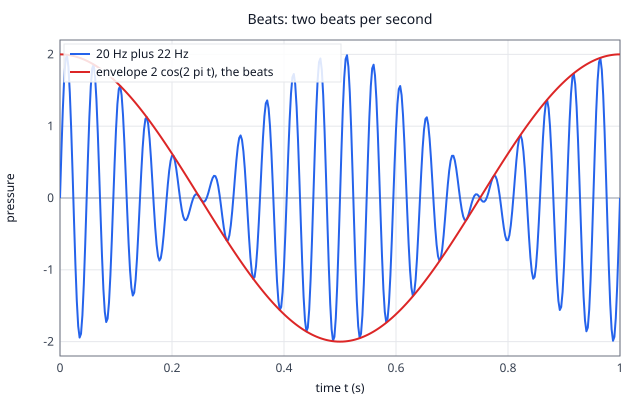

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = plot(sin(2*pi*20*t) + sin(2*pi*22*t), t, 0, 1);
p = show(p, plot(2*cos(pi*2*t), t, 0, 1));
p = legend(p, "20 Hz plus 22 Hz", "envelope 2 cos(2 pi t), the beats");
labels(title(p, "Beats: two beats per second"), "time t (s)", "pressure")

Tuners use this: two strings at 440 and 442 Hz beat twice a second, and the beats slow down and stop as the strings
come into tune.

Can the spectrum show the two tones apart? Take 440 Hz and 444 Hz. With 1024 samples the frequencies are 8 Hz apart, too
coarse; with 4096 samples (half a second) they are 2 Hz apart:

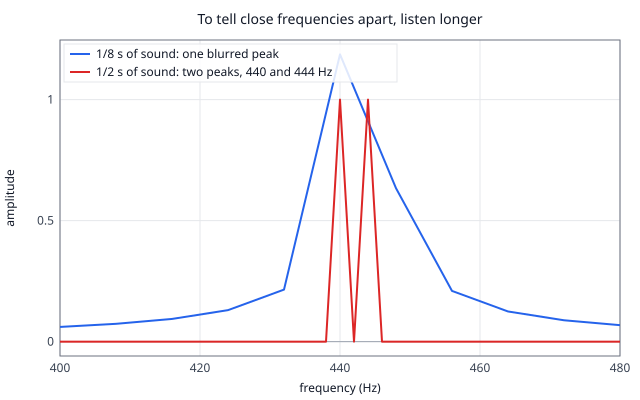

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
s2 = sin(2*pi*440*tt) + sin(2*pi*444*tt);
H1 = band(F, abs(fft(s2))/(N/2), 400, 480);
N4 = 4096;
t4 = (0:N4-1)/fs;
s4 = sin(2*pi*440*t4) + sin(2*pi*444*t4);
H4 = band(freqs(N4, 1/fs), abs(fft(s4))/(N4/2), 400, 480);
p = plot(H1(1), H1(2));
p = show(p, plot(H4(1), H4(2)));
p = legend(p, "1/8 s of sound: one blurred peak", "1/2 s of sound: two peaks, 440 and 444 Hz");
labels(title(p, "To tell close frequencies apart, listen longer"), "frequency (Hz)", "amplitude")

A recording of length $T$ separates frequencies only about $1/T$ apart. This is a property of waves, not of computers:
a note must last long enough to have a sharp pitch, and a very short click has no pitch at all. In quantum mechanics
the same fact becomes the uncertainty principle.

**Try this.** How long a recording is needed to separate 440 Hz from 440.5 Hz?

## 4. The Doppler effect

An ambulance passes at 25 m/s with its siren at 700 Hz. Coming towards you, it catches up a little with each wave it
sent, so the waves arrive closer together: $f' = f\,c/(c - v)$. Going away, $f' = f\,c/(c + v)$:

In [7]:
vs = 343 m/s;
v = 25 m/s;
up = eval(convert(700 Hz*vs/(vs - v), Hz), 4)
down = eval(convert(700 Hz*vs/(vs + v), Hz), 4)

755.0 Hz

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

652.4 Hz

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A drop in pitch of

In [8]:
eval(12*log(value(up)/value(down))/log(2), 3)

2.52

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

semitones, about a minor third, the familiar "neee-oooow". It happens smoothly as the ambulance passes, because only
the part of its velocity along the line of sight counts. Standing 10 m from the road:

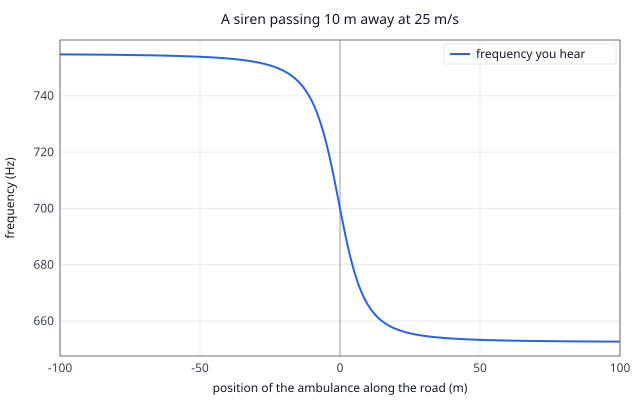

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = plot(700*343/(343 - 25*(-x)/sqrt(x^2 + 100)), x, -100, 100);
p = legend(p, "frequency you hear");
labels(title(p, "A siren passing 10 m away at 25 m/s"), "position of the ambulance along the road (m)", "frequency (Hz)")

Radar speed guns, ultrasound scans of blood flow and the measurement of how fast galaxies recede all use the Doppler
shift, the last with light instead of sound (lesson 6).

**Try this.** A bat flies at 5 m/s towards a wall, chirping at 40 kHz. What frequency does it hear in the echo? (The
wall hears a shifted frequency and sends it back from a stationary source to a moving listener: $f'' = f(c + v)/(c -
v)$.)

## Summary

* A sampled sound is a list of numbers; `fft` turns it into amplitudes at frequencies $k f_s/N$, listed by `freqs`.
* Timbre is the mix of harmonics: same fundamental, different peaks above it.
* Two close tones beat at $|f_1 - f_2|$; telling them apart in a spectrum takes a recording longer than
  $1/|f_1 - f_2|$.
* A source moving at $v$ along the line of sight is heard at $f\,c/(c \mp v)$.

Next: [dispersion](05-dispersion.ipynb), when waves of different frequencies travel at different speeds.

## Exercises

1. **Aliasing.** Sample a 7000 Hz tone at 8192 per second and compute its spectrum. Where does the peak appear? Why
   must CDs sample at more than twice 20 kHz?
2. **A chord.** Compute the spectrum of an A major chord: 440, 554.4 and 659.3 Hz. Which peaks are blurred, and why?
3. **Square wave.** Sample `sign(sin(2*pi*256*tt))` and find its spectrum. Compare with the Fourier series of
   lesson 3, exercise 4.
4. **Envelope.** Show with `simplify` that $\sin a + \sin b = 2\sin\frac{a+b}{2}\cos\frac{a-b}{2}$ by expanding both
   sides at numbers, or by plotting the difference.
5. **Train horn.** A train approaches at 30 m/s sounding 400 Hz, passes and leaves. What frequencies does a listener by
   the track hear before and after?
6. **Galaxies.** Light from a galaxy has its hydrogen line at 670 nm instead of 656.3 nm. For speeds much less than
   light, $\Delta\lambda/\lambda = v/c$. How fast is it receding?

## Hints and answers

* **Section 1, Try this.** At 1320 Hz, height 0.25 (a cosine has the same amplitude as a sine; only the phase differs).
* **Section 3, Try this.** About 2 s ($1/0.5$ Hz).
* **Section 4, Try this.** $40(343 + 5)/(343 - 5) \approx 41.2$ kHz.
* **Exercise 1.** At 1192 Hz: 7000 Hz is folded to $8192 - 7000$. A sample rate must exceed twice the highest
  frequency (the Nyquist limit), so 44.1 kHz covers hearing up to 20 kHz.
* **Exercise 2.** None of the three is a multiple of 8 Hz, so their energy leaks into neighbouring bins: each peak is
  lower and wider.
* **Exercise 3.** Odd harmonics only, with amplitudes $4/(\pi n)$: 1.27, 0.42, 0.25, …
* **Exercise 4.** For example `eval(sin(1) + sin(2) - 2*sin(3/2)*cos(1/2), 6)` is 0.
* **Exercise 5.** $400 \cdot 343/313 \approx 438$ Hz, then $400 \cdot 343/373 \approx 368$ Hz.
* **Exercise 6.** $v = c \cdot 13.7/656.3 \approx 6300$ km/s.

## Sources

1. J. W. Cooley and J. W. Tukey, "An algorithm for the machine calculation of complex Fourier series", *Mathematics
   of Computation* 19, 297–301 (1965).
2. C. Doppler, "Über das farbige Licht der Doppelsterne", *Abhandlungen der Königlichen Böhmischen Gesellschaft der
   Wissenschaften* 2, 465–482 (1842).
3. H. von Helmholtz, *Die Lehre von den Tonempfindungen* (1863), English translation *On the Sensations of Tone*,
   Dover (1954): timbre as the mix of harmonics.
4. N. H. Fletcher and T. D. Rossing, *The Physics of Musical Instruments*, 2nd ed., Springer (1998).